linear regression

In [63]:
import pandas as pd
df=pd.read_csv(r'C:\Users\anugr\OneDrive\Documents\Desktop\ML project\CORRECTED_2023_2026_NEPAL_FLOOD_WEATHER_KAGGLE.csv')

In [64]:
df['date']=pd.to_datetime(df['date'],dayfirst=True,errors='coerce')
df['month']=df['date'].dt.month

In [65]:
df=df.dropna(subset=['date','month'])

In [66]:
df['next_discharge'] = (
    df.groupby(['location', 'river'])['river_discharge_m3s'].shift(-1)
)

In [67]:
df.dropna(subset=['next_discharge'], inplace=True)

In [68]:
features=df[['elevation_m', 'precipitation_mm',
       'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c',
       'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct',
       'wind_speed_max_kmh', 'wind_gusts_max_kmh',
       'wind_direction_dominant_deg', 'river_discharge_m3s', 'month','location', 'river','basin']]

In [69]:
x=features
y=df['next_discharge']

In [70]:
x = pd.get_dummies(x,columns=['location', 'river', 'basin'],dtype=int)

In [71]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [72]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [73]:
import numpy as np
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print('mse:',mse)
print('mae:',mae)
print('rmse:',rmse)
print('r2:',r2)


mse: 504.0787301686704
mae: 6.686824456631307
rmse: 22.451697712392942
r2: 0.9196444241895624


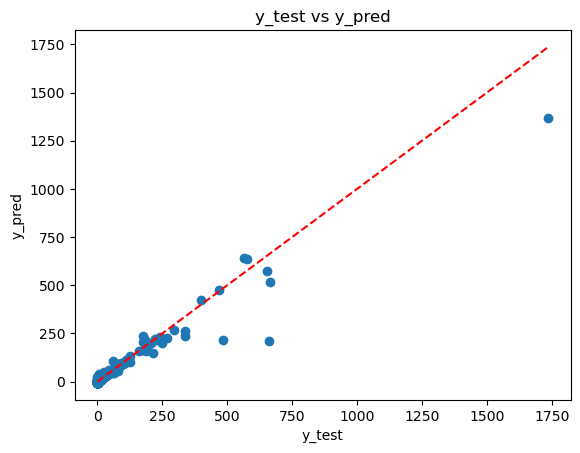

In [74]:
import matplotlib.pyplot as plt
plt.scatter(y_test,y_pred)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--')
plt.xlabel('y_test')
plt.ylabel('y_pred')
plt.title('y_test vs y_pred')
plt.show()


Random Forest Regressor

In [75]:
from sklearn.ensemble import RandomForestRegressor
rf_model=RandomForestRegressor()
rf_model.fit(x_train,y_train)
rf_pred=rf_model.predict(x_test)

In [76]:
r_mse=mean_squared_error(y_test,rf_pred)
r_mae=mean_absolute_error(y_test,rf_pred)
r_rmse=np.sqrt(r_mse)
r_R2=r2_score(y_test,rf_pred)
print('mse:',r_mse)
print('mae:',r_mae)
print('rmse:',r_rmse)
print('r2:',r_R2)

mse: 761.0143418399631
mae: 3.2101893738140426
rmse: 27.586488392688967
r2: 0.8786861218720945


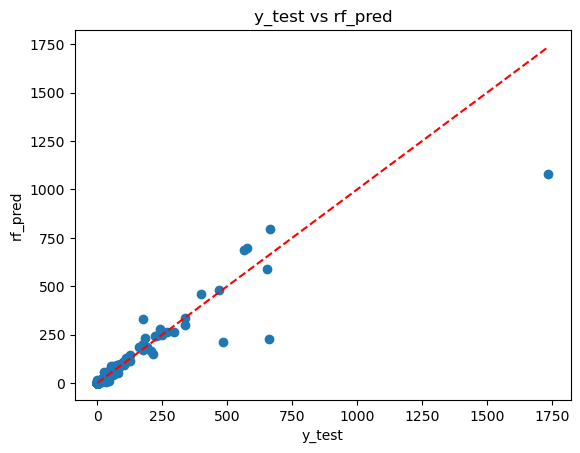

In [77]:
import matplotlib.pyplot as plt
plt.scatter(y_test,rf_pred)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--')
plt.xlabel('y_test')
plt.ylabel('rf_pred')
plt.title('y_test vs rf_pred')
plt.show()

Decision Tree Regressor

In [78]:
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor()
dt_model.fit(x_train, y_train)
dt_pred = dt_model.predict(x_test)


In [79]:
d_mse = mean_squared_error(y_test, dt_pred)
d_mae = mean_absolute_error(y_test, dt_pred)
d_rmse = np.sqrt(d_mse)
d_r2 = r2_score(y_test, dt_pred)

In [80]:
print("Decision Tree Results:")
print("MSE:", d_mse)
print("MAE:", d_mae)
print("RMSE:", d_rmse)
print("R2:", d_r2)

Decision Tree Results:
MSE: 1684.6959775142313
MAE: 4.096821631878558
RMSE: 41.04504814851886
R2: 0.7314413260535982


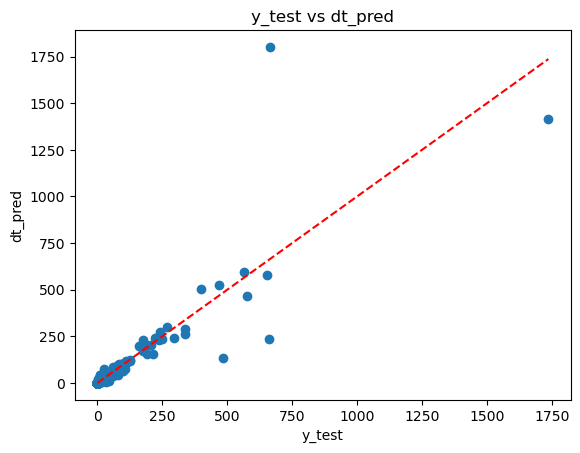

In [81]:
plt.scatter(y_test,dt_pred)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--')
plt.xlabel('y_test')
plt.ylabel('dt_pred')
plt.title('y_test vs dt_pred')
plt.show()

Compare

In [82]:
results=pd.DataFrame({
    "model":["lenear regression","random forest","decision tree"],
    "mse":[mse,r_mse,d_mse],
    "mae":[mae,r_mae,d_mae],
    "rmse":[rmse,r_rmse,d_rmse],
    "R2":[r2,r_R2,d_r2]
})

In [83]:
print(results)

               model          mse       mae       rmse        R2
0  lenear regression   504.078730  6.686824  22.451698  0.919644
1      random forest   761.014342  3.210189  27.586488  0.878686
2      decision tree  1684.695978  4.096822  41.045048  0.731441


Linear Regression is the best performer overall:

Lowest MSE (504) and RMSE (22.45) → smallest prediction errors.

Highest R² (0.920) → explains ~92% of the variance.

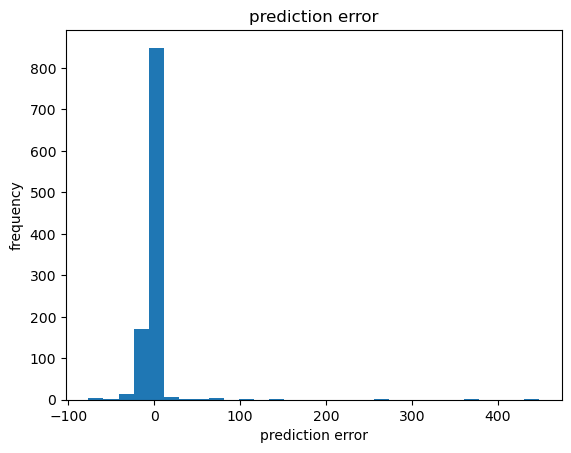

In [84]:
error=y_test-y_pred
plt.hist(error,bins=30)
plt.xlabel('prediction error')
plt.ylabel('frequency')
plt.title('prediction error')
plt.show()

In [85]:
print("Mean:", error.mean())
print("max:",error.max())
print("min:",error.min())

Mean: -0.1444502116522193
max: 448.1808314553747
min: -76.49771152731967


In [86]:
#Identify the dates/locations where the model made the largest prediction errors
error_df = pd.DataFrame({
    "date": df.loc[y_test.index, "date"],
    "location": df.loc[y_test.index, "location"],
    "river": df.loc[y_test.index, "river"],
    "actual": y_test,
    "predicted": y_pred,
    "error": error
})

largest_errors = error_df.reindex(error.abs().sort_values(ascending=False).index).head(10)
print(largest_errors)


            date location       river   actual    predicted       error
6208  2024-12-09    Kusum  West Rapti   661.22   213.039169  448.180831
5528  2024-06-07    Kusum  West Rapti  1736.80  1366.001390  370.798610
9238  2025-12-07    Kusum  West Rapti   482.06   217.978360  264.081640
5878  2024-10-08    Kusum  West Rapti   662.74   518.183790  144.556210
13108 2026-03-08    Kusum  West Rapti   335.51   234.355218  101.154782
5888  2024-11-08    Kusum  West Rapti   653.64   574.845314   78.794686
9518  2025-09-08    Kusum  West Rapti   563.94   640.437712  -76.497712
2406  2023-05-08    Kusum  West Rapti   335.51   260.921471   74.588529
10091 2025-06-10   Belsot      Kamala   214.77   150.467678   64.302322
12888 2026-12-07    Kusum  West Rapti   173.58   237.546497  -63.966497


In [87]:
#Identify the most important features affecting river discharge prediction.
importance = dt_model.feature_importances_
feat_names = x_train.columns
feat_imp = pd.DataFrame({"Feature": feat_names, "Importance": importance})
feat_imp = feat_imp.sort_values(by="Importance", ascending=False)
print(feat_imp.head(10))


                       Feature  Importance
11         river_discharge_m3s    0.831340
2   soil_moisture_0_100cm_m3m3    0.067768
1             precipitation_mm    0.064238
5             dew_point_mean_c    0.008038
12                       month    0.006875
4           temperature_mean_c    0.006848
6          precipitation_hours    0.005566
3                      rain_mm    0.003035
8           wind_speed_max_kmh    0.002247
7   relative_humidity_mean_pct    0.001658


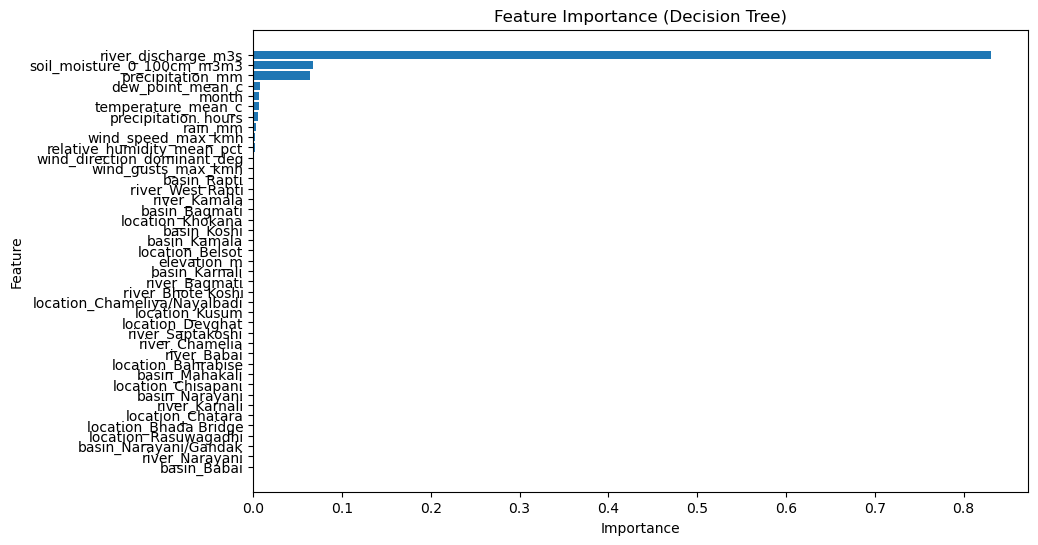

In [88]:
#Create a feature importance visualization for the best model.
plt.figure(figsize=(10,6))
plt.barh(feat_imp["Feature"], feat_imp["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance (Decision Tree)")
plt.gca().invert_yaxis()
plt.show()


In [89]:
# Example feature engineering
df["discharge_lag1"] = df.groupby(["location","river"])["river_discharge_m3s"].shift(1)
df["rain_lag1"] = df.groupby(["location","river"])["rain_mm"].shift(1)
df.dropna(inplace=True)

# Retrain Decision Tree with engineered features
feat_eng = features.copy()
feat_eng["discharge_lag1"] = df["discharge_lag1"]
feat_eng["rain_lag1"] = df["rain_lag1"]
feat_eng = feat_eng.dropna()

x_eng = pd.get_dummies(feat_eng, columns=["location","river","basin"], dtype=int)
y_eng = df["next_discharge"]

x_train_eng, x_test_eng, y_train_eng, y_test_eng = train_test_split(x_eng, y_eng, test_size=0.2, random_state=42)

dt_model_eng = DecisionTreeRegressor(max_depth=6, random_state=42)
dt_model_eng.fit(x_train_eng, y_train_eng)
dt_pred_eng = dt_model_eng.predict(x_test_eng)

print("R2 before feature engineering:", d_r2)
print("R2 after feature engineering:", r2_score(y_test_eng, dt_pred_eng))


R2 before feature engineering: 0.7314413260535982
R2 after feature engineering: 0.6554347347166052
